# Netflix Content Library: Exploratory Data Analysis
### Content mix, growth, geography, genres and ratings across 8,807 movies and TV shows

**Dataset:** `netflix_data.csv` · 8,807 titles · 12 columns · catalog snapshot through mid/late 2021  
**Goal:** understand content distribution, explore trends over time, and characterise what is on the platform.

---

## Table of Contents
1. [Business Context & Objectives](#1.-Business-Context-&-Objectives)
2. [Dataset Overview](#2.-Dataset-Overview)
3. [Data Preprocessing & Feature Engineering](#3.-Data-Preprocessing-&-Feature-Engineering)
4. [Exploratory Data Analysis](#4.-Exploratory-Data-Analysis)
5. [Key Insights](#5.-Key-Insights)
6. [Limitations & Next Steps](#6.-Limitations-&-Next-Steps)

## 1. Business Context & Objectives

Netflix is one of the world's largest streaming platforms, with over 200M subscribers as of mid-2021. This notebook analyses the **title-level metadata** of its catalog (cast, director, country, release year, rating, duration, genre) to answer:

| # | Question |
|---|----------|
| 1 | What is the balance between Movies and TV Shows, and how long are they? |
| 2 | How fast did the catalog grow, and when did it peak? |
| 3 | How fresh is the library (release year vs. year added)? |
| 4 | Which countries, genres and audience ratings define the platform? |
| 5 | How concentrated is the creative talent (directors, actors)? |

**Approach:** Understand the data → clean and engineer features → explore visually → interpret → state limitations.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---- Netflix-inspired style --------------------------------------------------
RED, CHAR, GREY, LGREY = "#E50914", "#221F1F", "#8C8C8C", "#D9D9D9"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (9, 5), "figure.dpi": 110,
    "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=[RED, CHAR, GREY, "#B20710", LGREY]),
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

DATA_PATH = "netflix_data.csv"   # adjust if the file lives elsewhere

## 2. Dataset Overview

| Column | Description |
|---|---|
| `show_id` | Unique identifier for each title |
| `type` | Movie or TV Show |
| `title` | Title of the content |
| `director` | Director(s), may contain several names |
| `cast` | Cast members, may contain several names |
| `country` | Country (or countries) of production |
| `date_added` | Date the title was added to Netflix |
| `release_year` | Original release year |
| `rating` | Content / audience rating |
| `duration` | Minutes for movies, seasons for TV shows |
| `listed_in` | Genre(s), may contain several |
| `description` | Short synopsis |

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Shape: 8,807 rows x 12 columns


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmmaker Kirsten Johnson stages his death in inventive and comical ways to help them both face the inevitable."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thabang Molaba, Dillon Windvogel, Natasha Thahane, Arno Greeff, Xolile Tshabalala, Getmore Sithole, Cindy Mahlangu, Ryle De Morny, Greteli Fincham, Sello Maake Ka-Ncube, Odwa Gwanya, Mekaila Mathys, Sandi Schultz, Duane Williams, Shamilla Miller, Patrick Mofokeng",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town teen sets out to prove whether a private-school swimming star is her sister who was abducted at birth."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabiha Akkari, Sofia Lesaffre, Salim Kechiouche, Noureddine Farihi, Geert Van Rampelberg, Bakary Diombera",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Action & Adventure","To protect his family from a powerful drug lord, skilled thief Mehdi and his expert team of robbers are pulled into a violent and deadly turf war."
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down among the incarcerated women at the Orleans Justice Center in New Orleans on this gritty reality series."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam Khan, Ahsaas Channa, Revathi Pillai, Urvi Singh, Arun Kumar",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV Comedies","In a city of coaching centers known to train India’s finest collegiate minds, an earnest but unexceptional student and his friends navigate campus life."


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [4]:
missing = (df.isna().sum().rename("missing").to_frame()
             .assign(pct=lambda d: d["missing"] / len(df) * 100)
             .query("missing > 0").sort_values("missing", ascending=False))
display(missing)
print("Duplicate rows:", df.duplicated().sum(), "| Duplicate show_id:", df["show_id"].duplicated().sum())

Duplicate rows: 0 | Duplicate show_id: 0


,missing,pct
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03


In [5]:
# Missing data by content type: director is missing for most TV Shows
display(df.assign(director_missing=df["director"].isna(), cast_missing=df["cast"].isna(), country_missing=df["country"].isna())
          .groupby("type")[["director_missing", "cast_missing", "country_missing"]].mean().mul(100).round(1))

,director_missing,cast_missing,country_missing
type,,,
Movie,3.10,7.70,7.20
TV Show,91.40,13.10,14.60


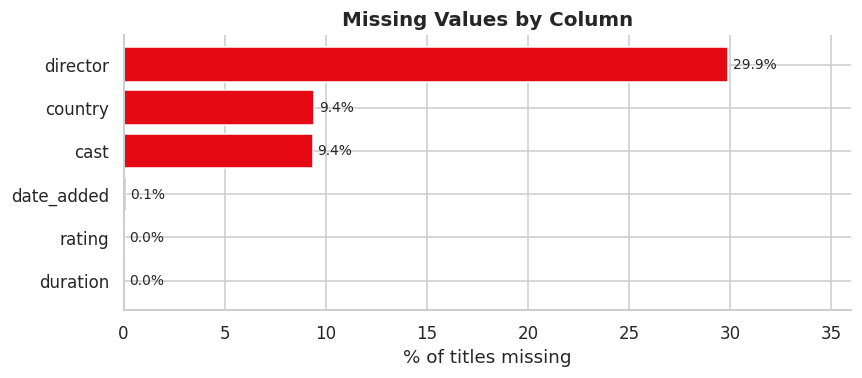

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
m = (df.isna().mean() * 100).sort_values()
m = m[m > 0]
ax.barh(m.index, m.values, color=RED)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3, fontsize=9)
ax.set(title="Missing Values by Column", xlabel="% of titles missing", xlim=(0, 36))
plt.tight_layout(); plt.show()

**Initial findings (raw data)**

- No duplicate titles or IDs.
- `director` is missing for ~30% of titles (and for >90% of TV Shows), `cast` and `country` for ~9% each; `date_added`, `rating` and `duration` are missing for under 0.1-0.2%.
- Three `rating` values are really runtimes (`74 min`, `84 min`, `66 min`) and the matching `duration` is blank.
- `date_added` is stored as text with stray whitespace.
- `duration` mixes units (minutes for movies, seasons for TV shows).

## 3. Data Preprocessing & Feature Engineering

Original columns are kept; derived columns are added alongside so every step stays auditable.

### Step 1 · Repair misplaced runtimes
Three stand-up specials stored their runtime in `rating`. Move it to `duration` and set the rating to missing.

In [7]:
misplaced = df["rating"].str.contains("min", na=False)
display(df.loc[misplaced, ["title", "type", "rating", "duration"]])

df.loc[misplaced, "duration"] = df.loc[misplaced, "rating"]
df.loc[misplaced, "rating"] = np.nan
print("Fixed:", misplaced.sum(), "rows")

Fixed: 3 rows


,title,type,rating,duration
5541,Louis C.K. 2017,Movie,74 min,NaN
5794,Louis C.K.: Hilarious,Movie,84 min,NaN
5813,Louis C.K.: Live at the Comedy Store,Movie,66 min,NaN


### Step 2 · Parse dates and split duration
`date_added` becomes a real datetime; `duration` is split into a numeric value and a unit.

In [8]:
df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), format="mixed")
df["year_added"]  = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month

dur = df["duration"].str.extract(r"(\d+)\s*(\w+)")
df["duration_value"] = dur[0].astype(float)
df["duration_unit"]  = dur[1].str.replace("s$", "", regex=True)

display(df.groupby("type")["duration_unit"].value_counts())
print("Date range:", df["date_added"].min().date(), "to", df["date_added"].max().date())

Date range: 2008-01-01 to 2021-09-25


type     duration_unit
Movie    min              6131
TV Show  Season           2676
Name: count, dtype: int64

### Step 3 · Content freshness
`content_lag_years` = year added to Netflix minus original release year.

In [9]:
df["content_lag_years"] = df["year_added"] - df["release_year"]
print("Titles added BEFORE their release year:", (df["content_lag_years"] < 0).sum(), "(kept; likely pre-release listings)")
df["content_lag_years"].describe()

Titles added BEFORE their release year: 14 (kept; likely pre-release listings)


count   8,797.00
mean        4.69
std         8.79
min        -3.00
25%         0.00
50%         1.00
75%         5.00
max        93.00
Name: content_lag_years, dtype: float64

### Step 4 · Missing values and multi-value fields

| Column | Treatment | Rationale |
|---|---|---|
| `director`, `cast`, `country` | Keep NaN for counting, label `Unknown` for display | Missing is informative (e.g. TV Shows rarely list directors) |
| `rating` | Label `Unknown` | Only 7 titles |
| `date_added`, `duration` | Leave as NaN | Under 0.2%, excluded from time analyses |
| `country`, `listed_in`, `director`, `cast` | **Exploded** into one row per value | A title can have several, so counts below are *mentions*, not unique titles |

In [10]:
df["rating"] = df["rating"].fillna("Unknown")

def explode(col, frame=df):
    # One row per (title, value) for a comma-separated column
    out = frame[["show_id", "type", col]].dropna(subset=[col]).copy()
    out[col] = out[col].str.split(",")
    out = out.explode(col)
    out[col] = out[col].str.strip()
    return out[out[col] != ""]

countries = explode("country")
genres    = explode("listed_in")
directors = explode("director")
actors    = explode("cast")

print(f"Unique countries: {countries['country'].nunique()} | genres: {genres['listed_in'].nunique()} | "
      f"directors: {directors['director'].nunique():,} | actors: {actors['cast'].nunique():,}")

Unique countries: 122 | genres: 42 | directors: 4,993 | actors: 36,439


### Step 5 · Validation

In [11]:
pd.Series({
    "Titles": len(df),
    "Movies / TV Shows": f"{(df.type=='Movie').sum():,} / {(df.type=='TV Show').sum():,}",
    "Release years": f"{df.release_year.min()} to {df.release_year.max()}",
    "Added between": f"{df.year_added.min():.0f} to {df.year_added.max():.0f}",
    "Titles with unknown rating": (df.rating == "Unknown").sum(),
}, name="Cleaned dataset").to_frame()

,Cleaned dataset
Titles,8807
Movies / TV Shows,"6,131 / 2,676"
Release years,1925 to 2021
Added between,2008 to 2021
Titles with unknown rating,7


## 4. Exploratory Data Analysis

In [12]:
def bar_labels(ax, fmt="{:,.0f}", **kw):
    for c in ax.containers:
        ax.bar_label(c, labels=[fmt.format(v) for v in c.datavalues], padding=3, fontsize=9, **kw)

### 4.1 Movies vs. TV Shows

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


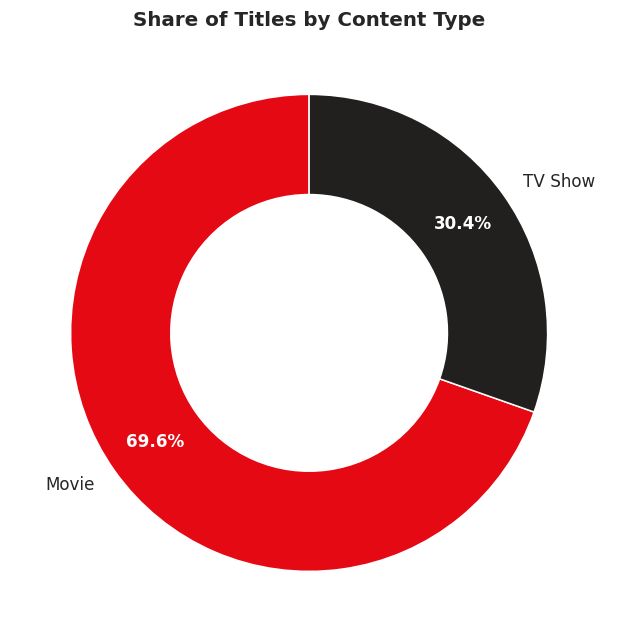

In [13]:
counts = df["type"].value_counts()
fig, ax = plt.subplots(figsize=(6, 6))
wedges, labels_, autotexts = ax.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90, colors=[RED, CHAR],
       wedgeprops=dict(width=0.42, edgecolor="white"), textprops={"fontsize": 11}, pctdistance=0.79)
for t in autotexts: t.set_color("white"); t.set_fontweight("bold")
ax.set_title("Share of Titles by Content Type")
plt.tight_layout(); plt.show()
print(counts)

> **Insight:** Movies make up **69.6%** of the catalog (6,131 titles) versus **30.4%** TV Shows (2,676).

### 4.2 Catalog growth: titles added per year

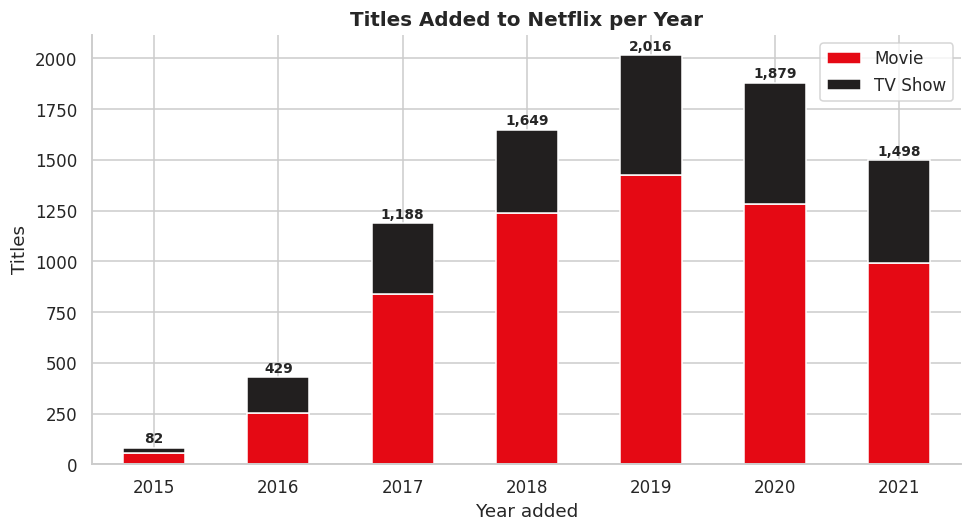

type,Movie,TV Show,total
year_added,,,
"2,015.00",56,26,82
"2,016.00",253,176,429
"2,017.00",839,349,1188
"2,018.00",1237,412,1649
"2,019.00",1424,592,2016
"2,020.00",1284,595,1879
"2,021.00",993,505,1498


In [14]:
added = df.groupby(["year_added", "type"]).size().unstack(fill_value=0).loc[2015:2021]
ax = added.plot(kind="bar", stacked=True, color=[RED, CHAR], rot=0, figsize=(9, 5))
ax.set(title="Titles Added to Netflix per Year", xlabel="Year added", ylabel="Titles")
ax.set_xticklabels([int(x) for x in added.index])
for i, tot in enumerate(added.sum(axis=1)):
    ax.text(i, tot + 25, f"{tot:,}", ha="center", fontsize=9, fontweight="bold")
ax.legend(title="")
plt.tight_layout(); plt.show()
added.assign(total=added.sum(axis=1))

> **Insight:** Additions grew from **82 titles in 2015 to 2,016 in 2019** (about 25x), then eased in 2020-21 (2021 covers only part of the year). Movies drove volume every year.

### 4.3 Is the TV Show share rising?

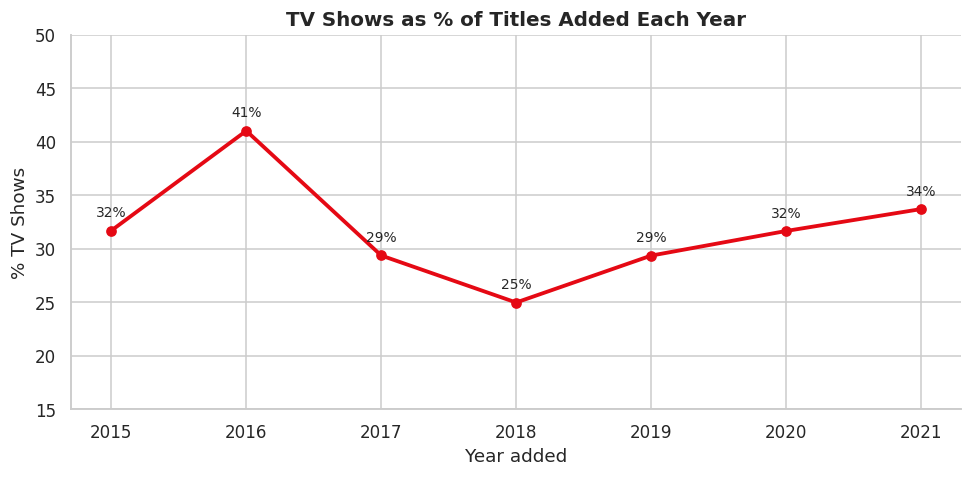

In [15]:
yearly = df.groupby(["year_added", "type"]).size().unstack(fill_value=0).loc[2015:2021]
tv_share = yearly["TV Show"] / yearly.sum(axis=1) * 100
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(tv_share.index.astype(int), tv_share, marker="o", color=RED, lw=2.5)
for x, y in tv_share.items():
    ax.annotate(f"{y:.0f}%", (x, y), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
ax.set(title="TV Shows as % of Titles Added Each Year", xlabel="Year added", ylabel="% TV Shows", ylim=(15, 50))
plt.tight_layout(); plt.show()

> **Insight:** The TV share is **not a steady climb**. It peaked at ~41% in 2016, dipped to ~25% in 2018 as movie additions surged, and has recovered to ~34% by 2021.

### 4.4 Duration: movie runtime and TV seasons

Movie mean 99.6 min, median 98 | TV mean 1.76 seasons, 67% have a single season


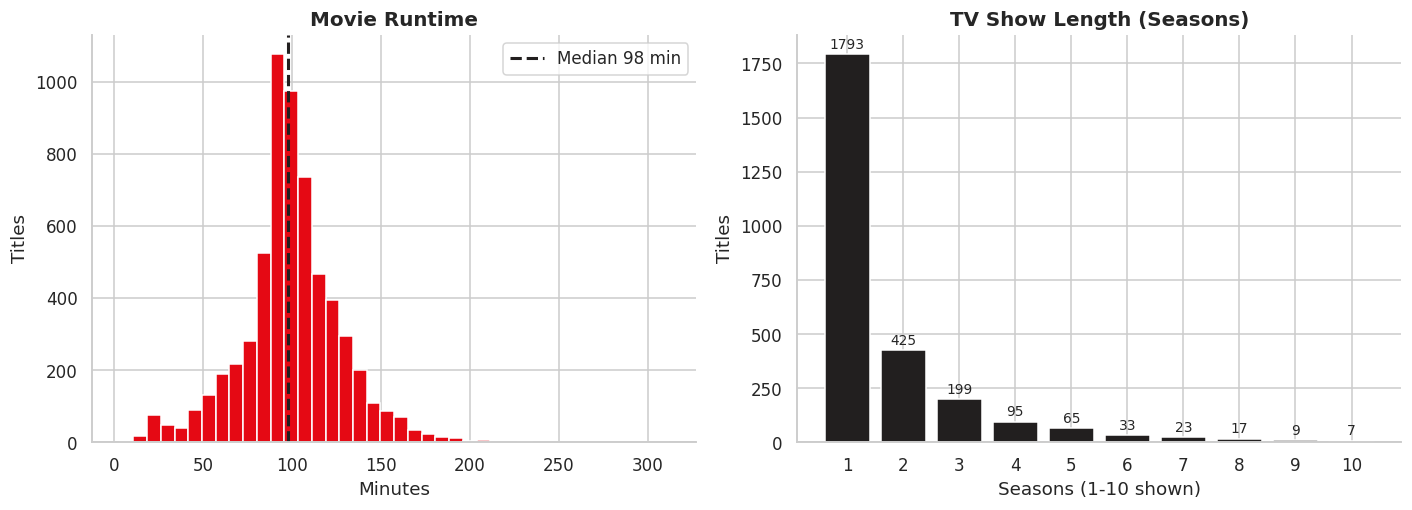

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
mv = df.loc[df.type == "Movie", "duration_value"].dropna()
axes[0].hist(mv, bins=40, color=RED, edgecolor="white")
axes[0].axvline(mv.median(), color=CHAR, ls="--", lw=2, label=f"Median {mv.median():.0f} min")
axes[0].set(title="Movie Runtime", xlabel="Minutes", ylabel="Titles"); axes[0].legend()

tv = df.loc[df.type == "TV Show", "duration_value"].dropna().astype(int)
s = tv.value_counts().sort_index().reindex(range(1, 11), fill_value=0)
axes[1].bar(s.index, s.values, color=CHAR)
axes[1].bar_label(axes[1].containers[0], padding=2, fontsize=9)
axes[1].set(title="TV Show Length (Seasons)", xlabel="Seasons (1-10 shown)", ylabel="Titles")
axes[1].set_xticks(range(1, 11))
plt.tight_layout(); plt.show()
print(f"Movie mean {mv.mean():.1f} min, median {mv.median():.0f} | TV mean {tv.mean():.2f} seasons, {(tv == 1).mean() * 100:.0f}% have a single season")

> **Insight:** The typical movie runs **~98 minutes** (mean ~100). **67%** of TV Shows have just **one season**, so the catalog is dominated by limited series and new shows.

### 4.5 Release years in the catalog

Released 2015 or later: 70.6% | before 2000: 6.0%


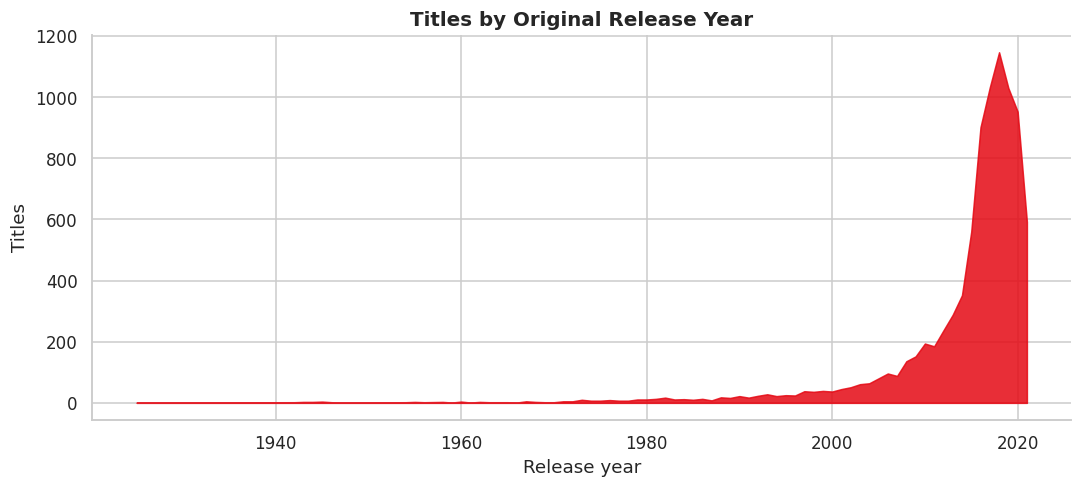

In [17]:
ry = df["release_year"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.fill_between(ry.index, ry.values, color=RED, alpha=0.85)
ax.set(title="Titles by Original Release Year", xlabel="Release year", ylabel="Titles")
plt.tight_layout(); plt.show()
print(f"Released 2015 or later: {(df.release_year >= 2015).mean() * 100:.1f}% | before 2000: {(df.release_year < 2000).mean() * 100:.1f}%")

> **Insight:** The library is **recent-heavy**: **70.6%** of titles were released in 2015 or later, and only **6%** before 2000, with a thin long tail of classics going back to 1925.

### 4.6 Content freshness: release year vs. year added

Same year: 37.0% | within 1 year: 55.0%


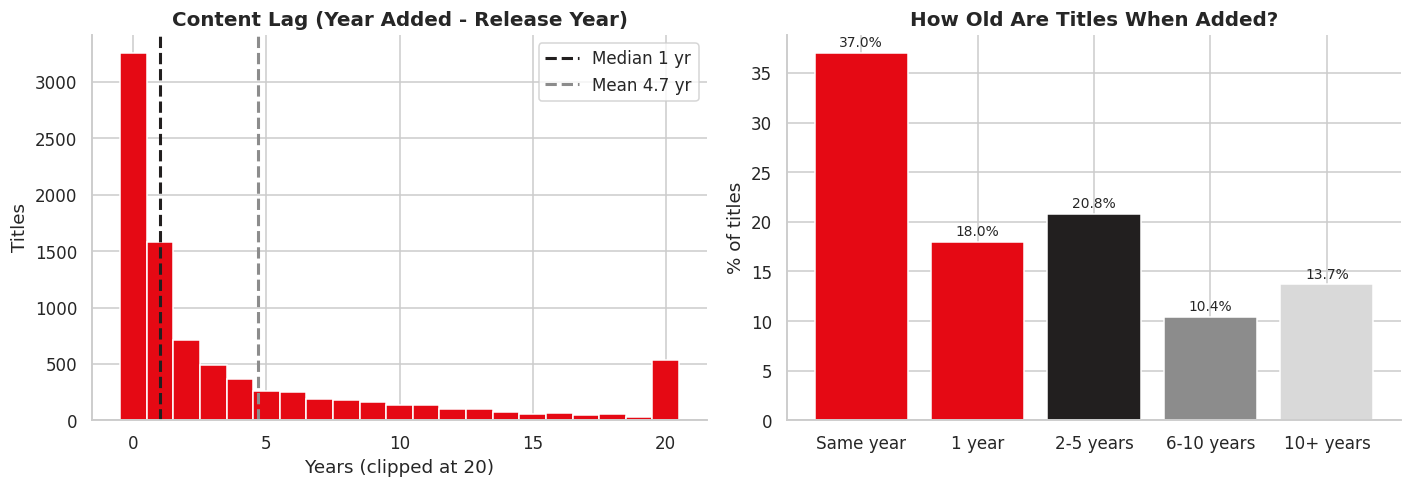

In [18]:
lag = df["content_lag_years"].dropna()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].hist(lag.clip(0, 20), bins=np.arange(-0.5, 21.5, 1), color=RED, edgecolor="white")
axes[0].axvline(lag.median(), color=CHAR, ls="--", lw=2, label=f"Median {lag.median():.0f} yr")
axes[0].axvline(lag.mean(), color=GREY, ls="--", lw=2, label=f"Mean {lag.mean():.1f} yr")
axes[0].set(title="Content Lag (Year Added - Release Year)", xlabel="Years (clipped at 20)", ylabel="Titles"); axes[0].legend()

buckets = pd.cut(lag, [-100, 0, 1, 5, 10, 200], labels=["Same year", "1 year", "2-5 years", "6-10 years", "10+ years"])
b = buckets.value_counts(normalize=True).sort_index() * 100
axes[1].bar(b.index.astype(str), b.values, color=[RED, RED, CHAR, GREY, LGREY])
axes[1].bar_label(axes[1].containers[0], fmt="%.1f%%", padding=2, fontsize=9)
axes[1].set(title="How Old Are Titles When Added?", ylabel="% of titles")
plt.tight_layout(); plt.show()
print(f"Same year: {(lag <= 0).mean() * 100:.1f}% | within 1 year: {(lag <= 1).mean() * 100:.1f}%")

> **Insight:** **37%** of titles were added in the year they were released and **55%** within a year (median lag: **1 year**). The mean is **4.7 years** because a back-catalog of older titles stretches the tail.

### 4.7 Where does the content come from?

Share of titles with a listed country:
country
United States     46.3 %
India             13.1 %
United Kingdom    10.1 %
Canada             5.6 %
France             4.9 %
Name: count, dtype: str


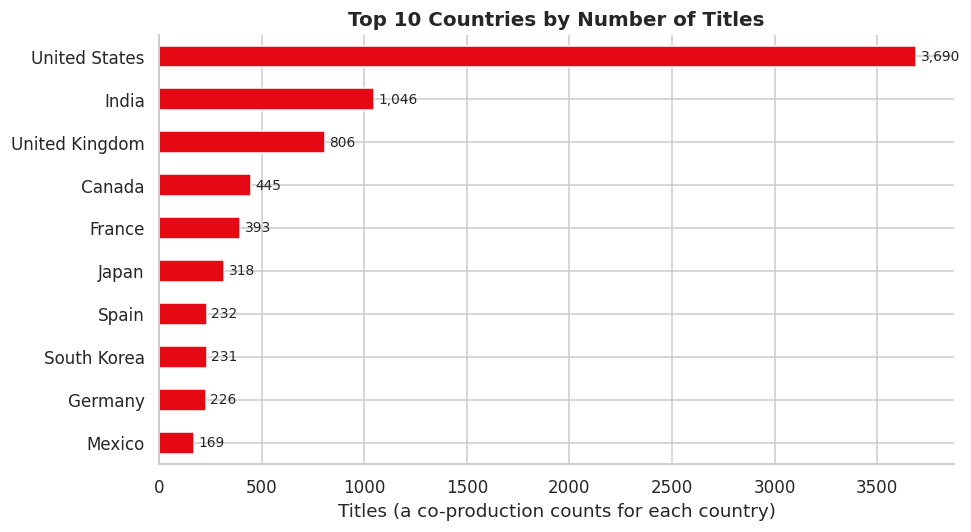

In [19]:
top_c = countries["country"].value_counts().head(10)
ax = top_c.sort_values().plot(kind="barh", color=RED, figsize=(9, 5))
ax.set(title="Top 10 Countries by Number of Titles", xlabel="Titles (a co-production counts for each country)", ylabel="")
bar_labels(ax)
plt.tight_layout(); plt.show()

share = top_c / df["country"].notna().sum() * 100
print("Share of titles with a listed country:"); print(share.round(1).head(5).astype(str) + " %")

> **Insight:** The **United States leads with 3,690 titles (~46% of titles with a listed country)**, followed by **India (1,046)** and the **UK (806)**. Canada, France, Japan, Spain, South Korea and Germany add real international depth.

### 4.8 Movie vs. TV mix by country

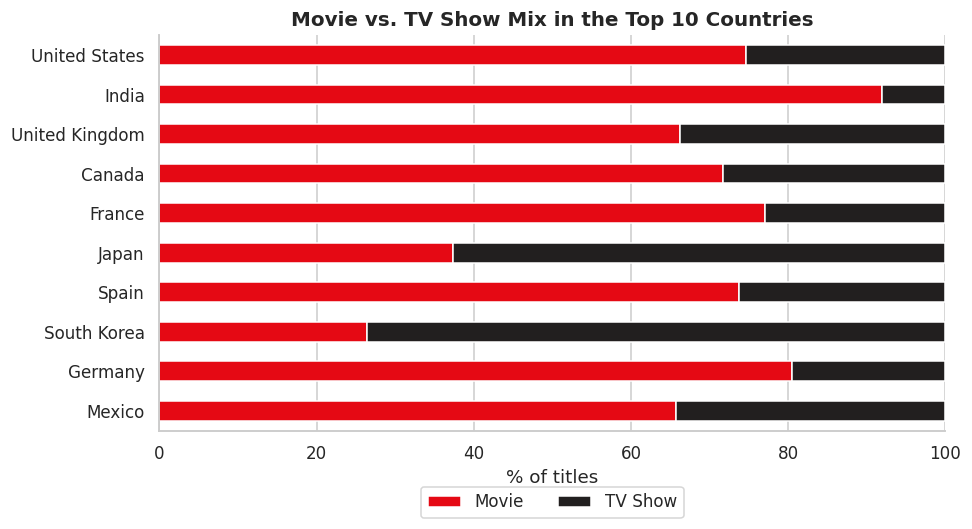

country,United States,India,United Kingdom,Canada,France,Japan,Spain,South Korea,Germany,Mexico
TV Show %,25.40,8.00,33.70,28.30,22.90,62.60,26.30,73.60,19.50,34.30


In [20]:
top10 = top_c.index
mix = (countries[countries.country.isin(top10)].groupby(["country", "type"]).size().unstack(fill_value=0).loc[top10])
mix_pct = mix.div(mix.sum(axis=1), axis=0) * 100
ax = mix_pct.iloc[::-1].plot(kind="barh", stacked=True, color=[RED, CHAR], figsize=(9, 5))
ax.set(title="Movie vs. TV Show Mix in the Top 10 Countries", xlabel="% of titles", ylabel="", xlim=(0, 100))
ax.legend(title="", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.tight_layout(); plt.show()
mix_pct["TV Show"].round(1).to_frame("TV Show %").T

> **Insight:** Mix varies sharply by country. **India is movie-heavy**, while **South Korea and Japan lean toward TV**, reflecting their series and anime output.

### 4.9 Growth by country

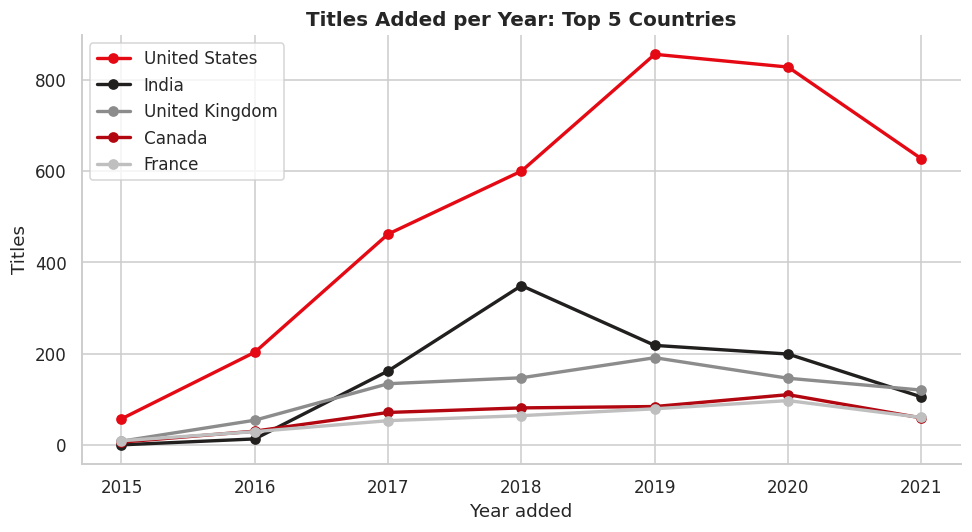

In [21]:
top5 = list(top_c.index[:5])
cy = (df.assign(country=df.country.str.split(",")).explode("country", ignore_index=True)
        .assign(country=lambda d: d.country.str.strip()))
cy = cy[cy.country.isin(top5) & cy.year_added.between(2015, 2021)]
tbl = cy.groupby(["year_added", "country"]).size().unstack(fill_value=0)[top5]
ax = tbl.plot(marker="o", lw=2.2, figsize=(9, 5), color=[RED, CHAR, GREY, "#B20710", "#BFBFBF"])
ax.set(title="Titles Added per Year: Top 5 Countries", xlabel="Year added", ylabel="Titles")
ax.set_xticks(tbl.index); ax.set_xticklabels([int(x) for x in tbl.index]); ax.legend(title="")
plt.tight_layout(); plt.show()

> **Insight:** The **US peaked in 2019 (856 titles)** and **India in 2018 (349)**. India ramped fastest (13 titles in 2016 to 349 in 2018) before easing, and is clearly the second pillar of the catalog.

### 4.10 Genres

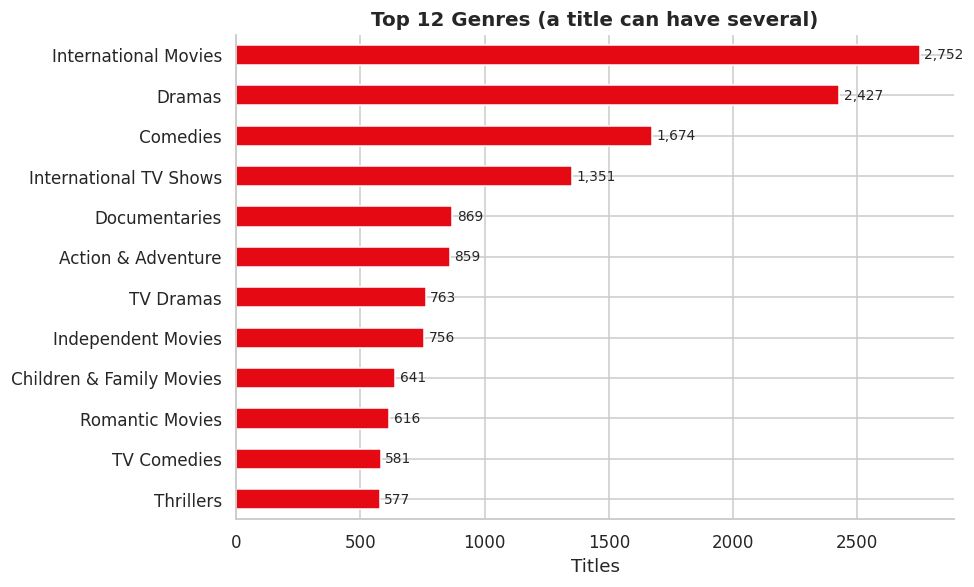

In [22]:
top_g = genres["listed_in"].value_counts().head(12)
ax = top_g.sort_values().plot(kind="barh", color=RED, figsize=(9, 5.5))
ax.set(title="Top 12 Genres (a title can have several)", xlabel="Titles", ylabel="")
bar_labels(ax)
plt.tight_layout(); plt.show()

> **Insight:** **International Movies (2,752)** and **Dramas (2,427)** lead, followed by Comedies (1,674) and International TV Shows (1,351). 42 distinct genres exist in total.

### 4.11 Genres by content type

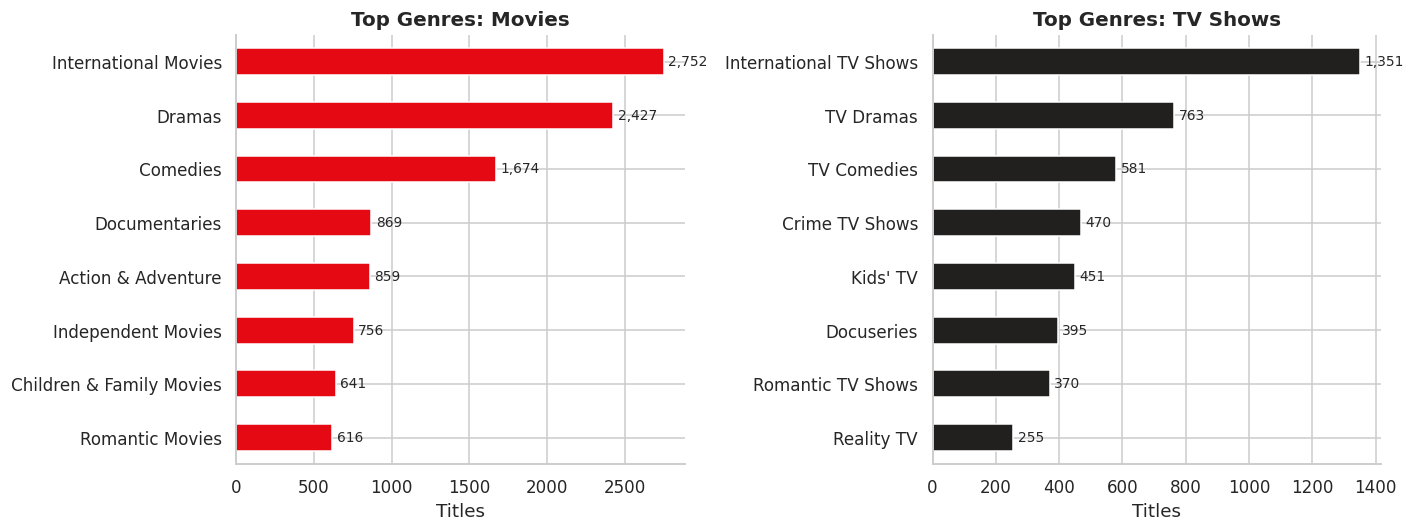

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (t, col) in zip(axes, [("Movie", RED), ("TV Show", CHAR)]):
    g = genres[genres.type == t]["listed_in"].value_counts().head(8)
    g.sort_values().plot(kind="barh", ax=ax, color=col)
    ax.set(title=f"Top Genres: {t}s", xlabel="Titles", ylabel="")
    bar_labels(ax)
plt.tight_layout(); plt.show()

> **Insight:** Movies centre on **International Movies, Dramas and Comedies**; TV Shows on **International TV Shows, TV Dramas, TV Comedies and Crime TV Shows**.

### 4.12 Country x genre heatmap

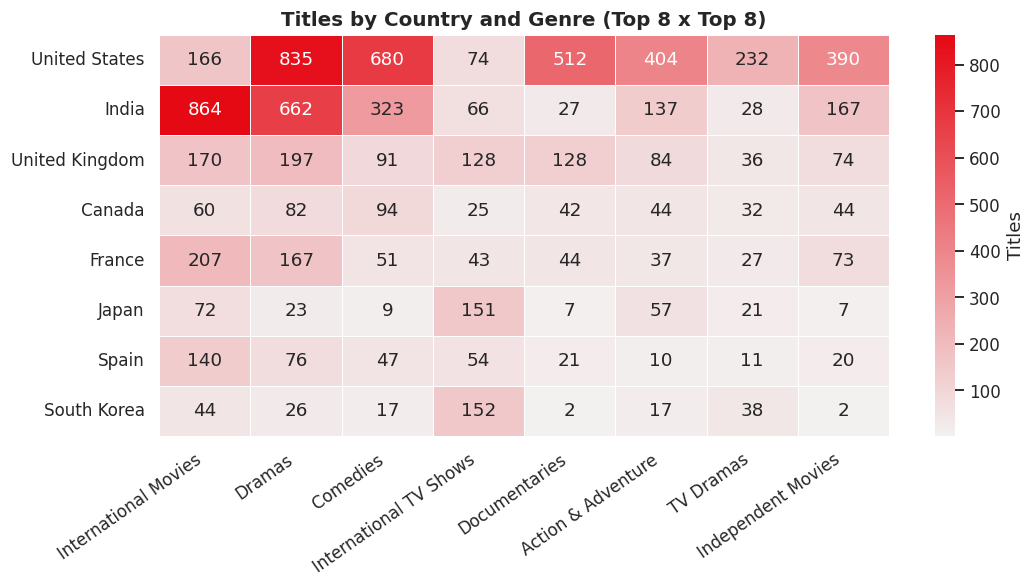

In [24]:
cg = (df[["show_id", "country", "listed_in"]].dropna()
        .assign(country=lambda d: d.country.str.split(","), listed_in=lambda d: d.listed_in.str.split(","))
        .explode("country", ignore_index=True).explode("listed_in", ignore_index=True))
cg["country"] = cg["country"].str.strip(); cg["listed_in"] = cg["listed_in"].str.strip()
tc, tg = top_c.index[:8], top_g.index[:8]
heat = pd.crosstab(cg.country, cg.listed_in).loc[tc, tg]
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.heatmap(heat, annot=True, fmt="d", cmap=sns.light_palette(RED, as_cmap=True), linewidths=0.5, ax=ax, cbar_kws={"label": "Titles"})
ax.set(title="Titles by Country and Genre (Top 8 x Top 8)", xlabel="", ylabel="")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

> **Insight:** Each market has a signature: **India is dominated by International Movies (864) and Dramas (662)**, while the US spreads across Dramas (835), Documentaries (512) and Action & Adventure (404).

### 4.13 Audience ratings

TV-MA + TV-14: 61.0% | TV-Y + TV-Y7: 7.3%


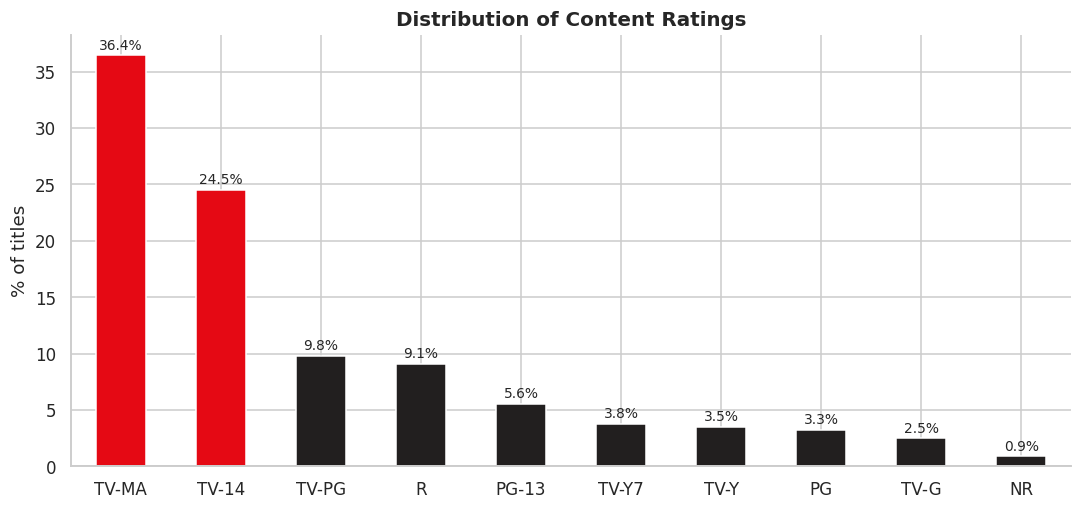

In [25]:
r = df.loc[df.rating != "Unknown", "rating"].value_counts(normalize=True) * 100
r = r.head(10)
ax = r.plot(kind="bar", color=[RED if k in ("TV-MA", "TV-14") else CHAR for k in r.index], rot=0, figsize=(10, 4.8))
ax.set(title="Distribution of Content Ratings", xlabel="", ylabel="% of titles")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=2, fontsize=9)
plt.tight_layout(); plt.show()
print(f"TV-MA + TV-14: {r[['TV-MA','TV-14']].sum():.1f}% | TV-Y + TV-Y7: {r[['TV-Y','TV-Y7']].sum():.1f}%")

> **Insight:** **61%** of titles are TV-MA or TV-14, aimed at teens and adults. Only **7.3%** (TV-Y, TV-Y7) are made specifically for young children.

### 4.14 Ratings by content type

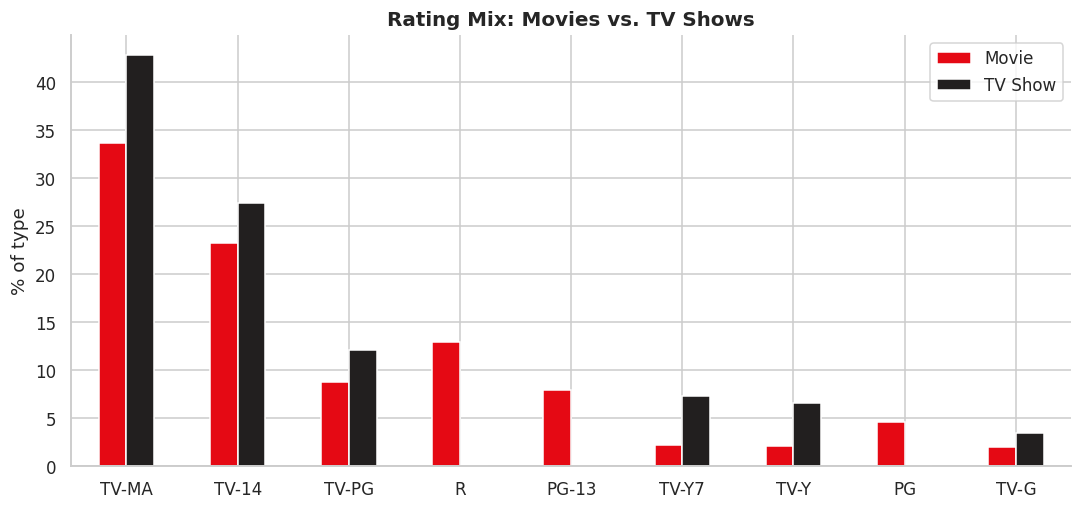

In [26]:
order = ["TV-MA", "TV-14", "TV-PG", "R", "PG-13", "TV-Y7", "TV-Y", "PG", "TV-G"]
rt = (pd.crosstab(df.type, df.rating, normalize="index") * 100)[order].T
ax = rt.plot(kind="bar", color=[RED, CHAR], rot=0, figsize=(10, 4.8))
ax.set(title="Rating Mix: Movies vs. TV Shows", xlabel="", ylabel="% of type")
ax.legend(title="")
plt.tight_layout(); plt.show()

> **Insight:** Movies carry the theatrical ratings (R, PG-13, PG) while TV Shows are almost entirely TV-rated, and TV Shows are noticeably heavier in TV-MA (43%) and children's ratings (TV-Y/Y7).

### 4.15 Seasonality of additions

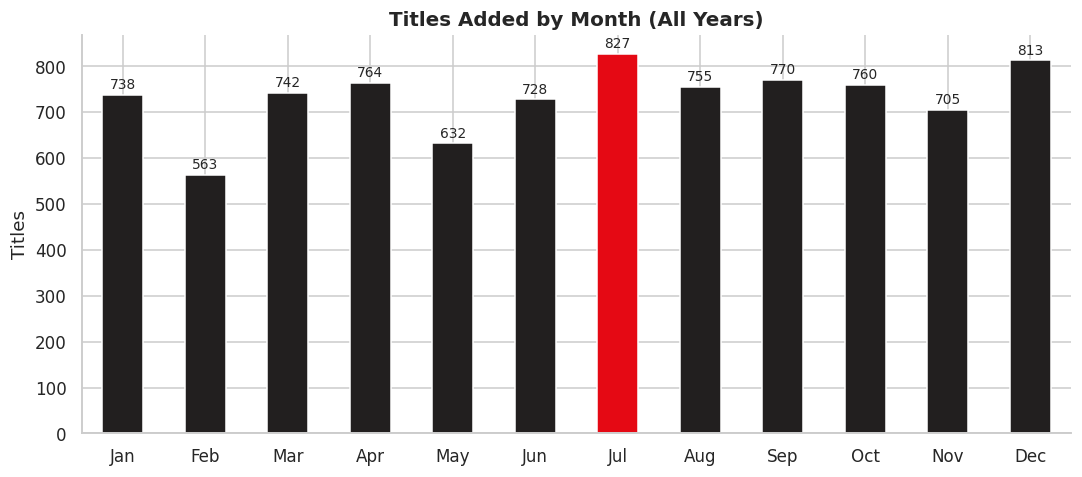

In [27]:
months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
mc = df["month_added"].value_counts().sort_index()
ax = pd.Series(mc.values, index=months).plot(kind="bar", color=[RED if v == mc.max() else CHAR for v in mc.values], rot=0, figsize=(10, 4.5))
ax.set(title="Titles Added by Month (All Years)", xlabel="", ylabel="Titles")
ax.bar_label(ax.containers[0], padding=2, fontsize=9)
plt.tight_layout(); plt.show()

> **Insight:** Additions are fairly even through the year, with **July and December** the busiest months and **February** the quietest.

### 4.16 Creative footprint: directors and cast

Unique directors: 4,993 | appear on only one title: 3,970 (79.5%)


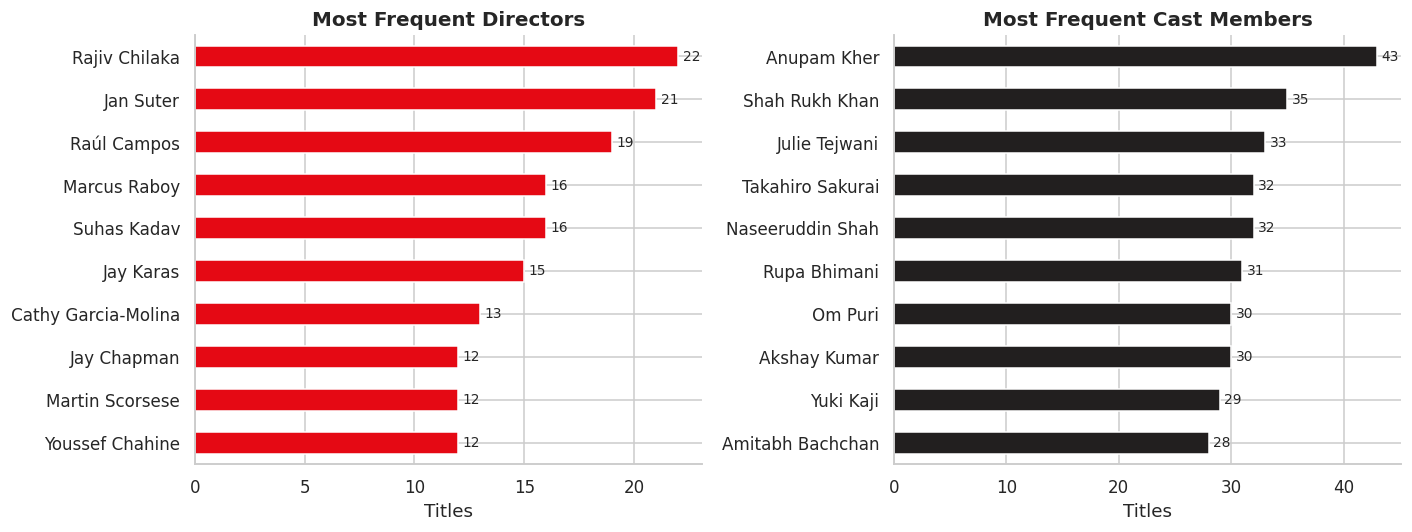

In [28]:
dvc = directors["director"].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
dvc.head(10).sort_values().plot(kind="barh", ax=axes[0], color=RED)
axes[0].set(title="Most Frequent Directors", xlabel="Titles", ylabel=""); bar_labels(axes[0])
actors["cast"].value_counts().head(10).sort_values().plot(kind="barh", ax=axes[1], color=CHAR)
axes[1].set(title="Most Frequent Cast Members", xlabel="Titles", ylabel=""); bar_labels(axes[1])
plt.tight_layout(); plt.show()
once = (dvc == 1).sum()
print(f"Unique directors: {len(dvc):,} | appear on only one title: {once:,} ({once / len(dvc) * 100:.1f}%)")

> **Insight:** The creative landscape is **highly fragmented**: **4,993** unique directors, of which **3,970 (79.5%)** appear on a single title. Prolific names skew toward children's content, stand-up and Indian cinema. Director data is missing for >90% of TV Shows, so treat this as a metadata view, not a complete creator map.

## 5. Key Insights

| # | Insight | Evidence |
|---|---|---|
| 1 | **Movies dominate**, but TV is a meaningful and recovering share | 69.6% Movies; TV share 25% (2018) to 34% (2021) |
| 2 | **Growth peaked in 2019** | 82 titles (2015) to 2,016 (2019), then slower 2020-21 |
| 3 | **Fresh plus back-catalog** | 37% added in release year, 55% within a year; median lag 1 yr, mean 4.7 |
| 4 | **A global library, US-anchored** | US 3,690 titles (~46% of those with a country), India 1,046, UK 806 |
| 5 | **Drama and international titles lead** | International Movies 2,752; Dramas 2,427 |
| 6 | **Built for grown-ups** | 61% TV-MA/TV-14; 7.3% TV-Y/Y7 |
| 7 | **Short-form series** | 67% of TV Shows have one season; movies run ~98 min |
| 8 | **Fragmented creative base** | 79.5% of directors appear once |

## 6. Limitations & Next Steps

- **Library, not performance:** no views, watch time, revenue or cost data, so nothing here measures success.
- **Snapshot:** the data runs to late 2021 and 2021 is a partial year.
- **Missing metadata:** director (30%), cast and country (9%) are incomplete, especially for TV Shows.
- **Multi-value counting:** exploded country, genre, director and cast counts are *mentions*, so shares can exceed 100% in total.
- **Date semantics:** `date_added` is when a title was listed, and 14 titles were added before their release year.
- **Next steps:** join external viewership/IMDb data, add text analysis of `description`, and cluster titles by genre and country.

---
*Prepared as an EDA project submission · Netflix Content Library Analysis*